# 📧 Spam Email Detection

In [1]:
# importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
df = pd.read_csv('spam mail.csv')

In [3]:
df.head()

,Category,Masseges
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5572 non-null   object
 1   Masseges  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [5]:
# check for missing values
df.isnull().sum()

Category    0
Masseges    0
dtype: int64

In [6]:
# count total duplicate rows
df.duplicated().sum()

np.int64(403)

In [9]:
# dropped the duplicated rows
df.drop_duplicates(inplace=True)

In [10]:
df.duplicated().sum()

np.int64(0)

In [15]:
print('rows','|','cols')
df.shape

rows | cols


(5169, 2)

In [16]:
df['Category'].value_counts()

Category
ham     4516
spam     653
Name: count, dtype: int64

In [17]:
# categories to numeric values
df['Category'] = df['Category'].map({
    "ham": 0,
    "spam": 1
})

In [24]:
# feature and target

X = df['Masseges']
y = df['Category']

In [26]:
# split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size= 0.2, random_state= 42, stratify=y)

In [27]:
# text feature extraction

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=3000
)

X_train = vectorizer.fit_transform(X_train)

X_test = vectorizer.transform(X_test)

In [32]:
# train model

model = LogisticRegression()
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [33]:
# make predictions
y_pred = model.predict(X_test)

In [39]:
# evaluate model

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print('accuracy ', round(accuracy, 4)) 
print('precision ', round(precision,4)) 
print('recall ', round(recall, 4)) 
print('f1 ', round(f1, 4)) 
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not spam", "spam"]
))

accuracy  0.9613
precision  0.9892
recall  0.7023
f1  0.8214
              precision    recall  f1-score   support

    Not spam       0.96      1.00      0.98       903
        spam       0.99      0.70      0.82       131

    accuracy                           0.96      1034
   macro avg       0.97      0.85      0.90      1034
weighted avg       0.96      0.96      0.96      1034



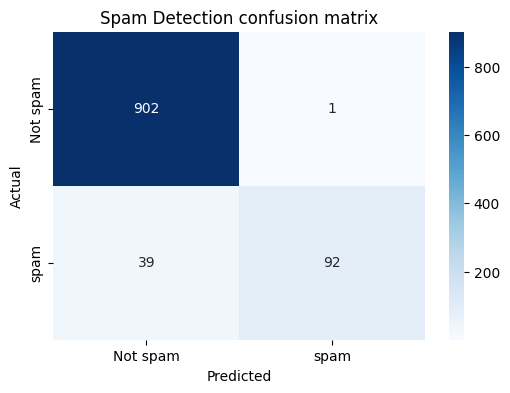

In [43]:
# confusin matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=['Not spam', 'spam'],
    yticklabels=['Not spam', 'spam']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title('Spam Detection confusion matrix')

plt.show()

In [45]:
# save model and vectorizer

joblib.dump(model, "spam_model.plk")
joblib.dump(vectorizer, "tfidf vectorizer")

['tfidf vectorizer']

In [47]:
# Test with a new message
new_message = [
    "Congratulations! You have won a free cash prize. Claim now!"
]

# Convert text into numerical features
new_message_vector = vectorizer.transform(new_message)

# Predict category
prediction = model.predict(new_message_vector)

# Predict probability
probability = model.predict_proba(
    new_message_vector
)

print("\n========== NEW MESSAGE PREDICTION ==========")

if prediction[0] == 1:
    print("Prediction: SPAM")
else:
    print("Prediction: NOT SPAM")

print(
    "Spam Probability:",
    round(probability[0][1] * 100, 2),
    "%"
)

print("\nProject completed successfully!")



========== NEW MESSAGE PREDICTION ==========
Prediction: SPAM
Spam Probability: 93.53 %

Project completed successfully!
